In [3]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

# Set random seed for consistent outputs
np.random.seed(42)

n_rows = 1000

# 1. Booking IDs & Timestamps
booking_ids = [f"IN-HTL-{str(i).zfill(6)}" for i in range(1001, 1001 + n_rows)]
start_date = datetime(2025, 1, 1)
check_in_dates = [start_date + timedelta(days=int(np.random.randint(0, 365))) for _ in range(n_rows)]

# Seasons and Months
months = [d.strftime("%b") for d in check_in_dates]
years = [d.year for d in check_in_dates]

def get_season(date_obj):
    m = date_obj.month
    if m in [10, 11, 12, 1, 2]:
        return "Peak (Winter/Weddings)"
    elif m in [3, 4, 5, 6]:
        return "Summer (Leisure)"
    else:
        return "Monsoon (Lean)"

seasons = [get_season(d) for d in check_in_dates]

# 2. Hotel Property Metadata
indian_cities = ["Mumbai", "New Delhi", "Bengaluru", "Goa", "Jaipur", "Hyderabad"]
city_weights = [0.25, 0.20, 0.20, 0.15, 0.10, 0.10]
cities = np.random.choice(indian_cities, size=n_rows, p=city_weights)
properties = [f"AtliQ Grand {c}" for c in cities]

room_types = np.random.choice(["Standard", "Deluxe", "Executive Suite", "Presidential Suite"], size=n_rows, p=[0.40, 0.35, 0.18, 0.07])

# 3. Customer Demographics & Behavior
guest_firsts = ["Aarav", "Ananya", "Rohan", "Priya", "Vikram", "Neha", "Arjun", "Kavya", "Siddharth", "Pooja"]
guest_lasts = ["Sharma", "Verma", "Patel", "Reddy", "Iyer", "Nair", "Mehta", "Singh", "J Joshi", "Chopra"]
guest_names = [f"{np.random.choice(guest_firsts)} {np.random.choice(guest_lasts)}" for _ in range(n_rows)]
customer_ids = [f"CUST-{np.random.randint(10000, 99999)}" for _ in range(n_rows)]

origin_states = np.random.choice(["Maharashtra", "Delhi NCR", "Karnataka", "Tamil Nadu", "Gujarat", "West Bengal"], size=n_rows)
genders = np.random.choice(["Male", "Female", "Other"], size=n_rows, p=[0.52, 0.46, 0.02])
ages = np.random.randint(21, 68, size=n_rows)

customer_types = np.random.choice(["Solo Business", "Corporate Group", "Family Leisure", "Couple", "Friends Group"], size=n_rows, p=[0.25, 0.15, 0.30, 0.20, 0.10])
no_adults = [1 if ct in ["Solo Business"] else (2 if ct in ["Couple"] else np.random.randint(2, 5)) for ct in customer_types]
no_children = [np.random.randint(1, 3) if ct == "Family Leisure" else 0 for ct in customer_types]

is_repeated = np.random.choice([0, 1], size=n_rows, p=[0.82, 0.18])
loyalty_tiers = [np.random.choice(["Gold", "Platinum"], p=[0.7, 0.3]) if r == 1 else "Bronze/None" for r in is_repeated]

# 4. Booking Channels & Financials
channels = np.random.choice(["MakeMyTrip", "Goibibo", "Direct Website", "Direct Walk-In", "Corporate Desk", "Booking.com"], size=n_rows, p=[0.28, 0.18, 0.22, 0.07, 0.15, 0.10])
lead_times = np.random.exponential(scale=20, size=n_rows).astype(int) + 1
stay_nights = np.random.choice([1, 2, 3, 4, 5, 7], size=n_rows, p=[0.30, 0.35, 0.15, 0.10, 0.06, 0.04])

# Room pricing scale in INR
base_adr_map = {"Standard": 4800, "Deluxe": 7500, "Executive Suite": 13500, "Presidential Suite": 28000}
adrs = []
for rt, s in zip(room_types, seasons):
    multiplier = 1.35 if s == "Peak (Winter/Weddings)" else (0.85 if s == "Monsoon (Lean)" else 1.0)
    base = base_adr_map[rt] * multiplier
    adrs.append(round(base + np.random.randint(-400, 600), -2))

# Ancillary revenue streams
fn_b_spend = [round(adr * np.random.uniform(0.15, 0.40) * nights, -2) for adr, nights in zip(adrs, stay_nights)]
spa_other_spend = [round(np.random.choice([0, 800, 2500, 5000], p=[0.5, 0.25, 0.15, 0.10]), -2) for _ in range(n_rows)]

# Channel Commissions (OTAs charge 15-20%)
commission_rates = {"MakeMyTrip": 0.18, "Goibibo": 0.16, "Booking.com": 0.15, "Direct Website": 0.0, "Direct Walk-In": 0.0, "Corporate Desk": 0.05}
commission_cost = [round(adr * stay_nights[i] * commission_rates[channels[i]], 2) for i, adr in enumerate(adrs)]

# 5. Cancellations & Operational Logic
deposit_types = np.random.choice(["No Deposit", "Refundable", "Non-Refundable"], size=n_rows, p=[0.55, 0.30, 0.15])

# Calculate cancellation probability organically
cancellation_reasons_list = [
    "Change in Travel Plans", "Found Cheaper Alternative", "Personal Emergency",
    "Corporate Trip Rescheduled", "Flight Delayed/Cancelled", "Weather/Monsoon Issues"
]

booking_status = []
cancellation_reasons = []

for i in range(n_rows):
    # Higher lead times & OTA bookings have higher drop-off rates
    prob = 0.12 + (lead_times[i] / 200.0) + (0.15 if channels[i] in ["MakeMyTrip", "Goibibo"] else -0.05)
    if deposit_types[i] == "Non-Refundable":
        prob -= 0.15

    if np.random.rand() < max(0.05, min(prob, 0.48)):
        status = np.random.choice(["Cancelled", "No-Show"], p=[0.88, 0.12])
        booking_status.append(status)
        reason = np.random.choice(cancellation_reasons_list, p=[0.35, 0.25, 0.15, 0.12, 0.08, 0.05]) if status == "Cancelled" else "No-Show / Client Unreachable"
        cancellation_reasons.append(reason)
    else:
        booking_status.append("Checked-Out")
        cancellation_reasons.append("N/A - Stay Completed")

# Total Gross & Net Realized Revenue Calculation
gross_revenue = [round((adr * nights) + fnb + spa, 2) for adr, nights, fnb, spa in zip(adrs, stay_nights, fn_b_spend, spa_other_spend)]
net_realized_revenue = [
    round(gross - comm, 2) if status == "Checked-Out"
    else (round((adr * nights * 0.2) if dep == "Non-Refundable" else 0, 2))
    for gross, status, adr, nights, comm, dep in zip(gross_revenue, booking_status, adrs, stay_nights, commission_cost, deposit_types)
]

special_requests = np.random.choice([0, 1, 2, 3], size=n_rows, p=[0.4, 0.35, 0.18, 0.07])

# Assemble Master DataFrame
df_enterprise = pd.DataFrame({
    "booking_id": booking_ids,
    "customer_id": customer_ids,
    "customer_name": guest_names,
    "gender": genders,
    "age": ages,
    "origin_state": origin_states,
    "customer_segment": customer_types,
    "adults_count": no_adults,
    "children_count": no_children,
    "is_repeated_guest": is_repeated,
    "loyalty_tier": loyalty_tiers,
    "property_name": properties,
    "city": cities,
    "room_type": room_types,
    "booking_channel": channels,
    "season": seasons,
    "month": months,
    "year": years,
    "check_in_date": [d.strftime("%Y-%m-%d") for d in check_in_dates],
    "lead_time_days": lead_times,
    "stay_nights": stay_nights,
    "deposit_type": deposit_types,
    "special_requests_count": special_requests,
    "adr_inr": adrs,
    "fnb_spend_inr": fn_b_spend,
    "spa_other_spend_inr": spa_other_spend,
    "gross_revenue_inr": gross_revenue,
    "channel_commission_inr": commission_cost,
    "net_realized_revenue_inr": net_realized_revenue,
    "booking_status": booking_status,
    "cancellation_reason": cancellation_reasons
})

# Save to CSV
df_enterprise.to_csv("hotel_revenue_enterprise_1000.csv", index=False)
print("Enterprise dataset with 31 columns successfully created!")

Enterprise dataset with 31 columns successfully created!


In [4]:
# Load the generated dataset
df = pd.read_csv("hotel_revenue_enterprise_1000.csv")

# Display first five records
display(df.head())

# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check column names and data types
df.info()

# Statistical summary
display(df.describe())

# Check missing values
print(df.isnull().sum())

# Check duplicate records
print("Duplicate Records:", df.duplicated().sum())

,booking_id,customer_id,customer_name,gender,age,origin_state,customer_segment,adults_count,children_count,is_repeated_guest,...,deposit_type,special_requests_count,adr_inr,fnb_spend_inr,spa_other_spend_inr,gross_revenue_inr,channel_commission_inr,net_realized_revenue_inr,booking_status,cancellation_reason
0,IN-HTL-001001,CUST-59056,Kavya Chopra,Male,38,West Bengal,Solo Business,1,0,0,...,No Deposit,1,28400.0,42400.0,2500,243700.0,0.0,243700.0,Checked-Out,N/A - Stay Completed
1,IN-HTL-001002,CUST-73851,Neha Iyer,Male,63,Gujarat,Family Leisure,4,1,0,...,No Deposit,0,9800.0,8700.0,0,57700.0,0.0,57700.0,Checked-Out,N/A - Stay Completed
2,IN-HTL-001003,CUST-91502,Pooja J Joshi,Male,30,Tamil Nadu,Family Leisure,3,1,0,...,No Deposit,0,4000.0,2200.0,800,15000.0,0.0,15000.0,Checked-Out,N/A - Stay Completed
3,IN-HTL-001004,CUST-91418,Ananya Iyer,Male,44,West Bengal,Family Leisure,4,1,0,...,Non-Refundable,0,7900.0,14400.0,800,54700.0,6320.0,7900.0,Cancelled,Change in Travel Plans
4,IN-HTL-001005,CUST-80211,Neha Mehta,Male,24,Tamil Nadu,Corporate Group,2,0,0,...,No Deposit,0,7600.0,6800.0,0,29600.0,4104.0,25496.0,Checked-Out,N/A - Stay Completed


Dataset Shape: (1000, 31)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 31 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   booking_id                1000 non-null   object 
 1   customer_id               1000 non-null   object 
 2   customer_name             1000 non-null   object 
 3   gender                    1000 non-null   object 
 4   age                       1000 non-null   int64  
 5   origin_state              1000 non-null   object 
 6   customer_segment          1000 non-null   object 
 7   adults_count              1000 non-null   int64  
 8   children_count            1000 non-null   int64  
 9   is_repeated_guest         1000 non-null   int64  
 10  loyalty_tier              1000 non-null   object 
 11  property_name             1000 non-null   object 
 12  city                      1000 non-null   object 
 13  room_type                 1000 non-nul

,age,adults_count,children_count,is_repeated_guest,year,lead_time_days,stay_nights,special_requests_count,adr_inr,fnb_spend_inr,spa_other_spend_inr,gross_revenue_inr,channel_commission_inr,net_realized_revenue_inr
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.0,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000
mean,43.477000,2.289000,0.491000,0.167000,2025.0,20.304000,2.430000,0.904000,9856.40000,6706.400000,1112.700000,32484.70000,2418.930000,23164.155000
std,13.371846,1.061417,0.774932,0.373162,0.0,19.404539,1.476238,0.923925,6844.20647,7930.825747,1639.968966,35377.75914,3590.615438,31180.642903
min,21.000000,1.000000,0.000000,0.000000,2025.0,1.000000,1.000000,0.000000,3700.00000,700.000000,0.000000,4500.00000,0.000000,0.000000
25%,32.000000,1.000000,0.000000,0.000000,2025.0,6.000000,1.000000,0.000000,6100.00000,2500.000000,0.000000,13100.00000,0.000000,5581.250000
50%,43.000000,2.000000,0.000000,0.000000,2025.0,14.000000,2.000000,1.000000,7300.00000,4200.000000,0.000000,21950.00000,1350.000000,15046.000000
75%,55.000000,3.000000,1.000000,0.000000,2025.0,28.000000,3.000000,2.000000,10700.00000,7900.000000,800.000000,38300.00000,3298.500000,29125.000000
max,67.000000,4.000000,2.000000,1.000000,2025.0,141.000000,7.000000,3.000000,38400.00000,96700.000000,5000.000000,364900.00000,48132.000000,313700.000000


booking_id                  0
customer_id                 0
customer_name               0
gender                      0
age                         0
origin_state                0
customer_segment            0
adults_count                0
children_count              0
is_repeated_guest           0
loyalty_tier                0
property_name               0
city                        0
room_type                   0
booking_channel             0
season                      0
month                       0
year                        0
check_in_date               0
lead_time_days              0
stay_nights                 0
deposit_type                0
special_requests_count      0
adr_inr                     0
fnb_spend_inr               0
spa_other_spend_inr         0
gross_revenue_inr           0
channel_commission_inr      0
net_realized_revenue_inr    0
booking_status              0
cancellation_reason         0
dtype: int64
Duplicate Records: 0


In [5]:
df_clean = df.copy()

# Check missing values
print("Missing Values:")
print(df_clean.isnull().sum())

# Check duplicate booking IDs
print("Duplicates Before:",
      df_clean['booking_id'].duplicated().sum())

# Remove duplicate booking IDs
df_clean = df_clean.drop_duplicates(
    subset=['booking_id']
)

# Convert date column
df_clean['check_in_date'] = pd.to_datetime(
    df_clean['check_in_date'], errors='coerce'
)

# Check invalid values
print("Invalid ADR:",
      (df_clean['adr_inr'] <= 0).sum())

print("Invalid Stay Nights:",
      (df_clean['stay_nights'] <= 0).sum())

# Remove invalid records
df_clean = df_clean[
    (df_clean['adr_inr'] > 0) &
    (df_clean['stay_nights'] > 0) &
    (df_clean['check_in_date'].notna())
].copy()

print("Final Dataset Shape:", df_clean.shape)
print("Remaining Missing Values:",
      df_clean.isnull().sum().sum())

Missing Values:
booking_id                  0
customer_id                 0
customer_name               0
gender                      0
age                         0
origin_state                0
customer_segment            0
adults_count                0
children_count              0
is_repeated_guest           0
loyalty_tier                0
property_name               0
city                        0
room_type                   0
booking_channel             0
season                      0
month                       0
year                        0
check_in_date               0
lead_time_days              0
stay_nights                 0
deposit_type                0
special_requests_count      0
adr_inr                     0
fnb_spend_inr               0
spa_other_spend_inr         0
gross_revenue_inr           0
channel_commission_inr      0
net_realized_revenue_inr    0
booking_status              0
cancellation_reason         0
dtype: int64
Duplicates Before: 0
Invalid ADR: 0
Inval

In [6]:
df_clean.to_csv(
    "hotel_revenue_enterprise_1000_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [7]:
import sqlite3
import pandas as pd

# Connect to SQLite database
conn = sqlite3.connect("hotel_analytics.db")

# Load cleaned data into SQL table
df_clean.to_sql(
    "fact_bookings",
    conn,
    if_exists="replace",
    index=False
)

print("Data successfully loaded into SQL database!")

Data successfully loaded into SQL database!


In [8]:
query = """
SELECT *
FROM fact_bookings
LIMIT 5;
"""

sql_result = pd.read_sql(query, conn)

display(sql_result)

,booking_id,customer_id,customer_name,gender,age,origin_state,customer_segment,adults_count,children_count,is_repeated_guest,...,deposit_type,special_requests_count,adr_inr,fnb_spend_inr,spa_other_spend_inr,gross_revenue_inr,channel_commission_inr,net_realized_revenue_inr,booking_status,cancellation_reason
0,IN-HTL-001001,CUST-59056,Kavya Chopra,Male,38,West Bengal,Solo Business,1,0,0,...,No Deposit,1,28400.0,42400.0,2500,243700.0,0.0,243700.0,Checked-Out,N/A - Stay Completed
1,IN-HTL-001002,CUST-73851,Neha Iyer,Male,63,Gujarat,Family Leisure,4,1,0,...,No Deposit,0,9800.0,8700.0,0,57700.0,0.0,57700.0,Checked-Out,N/A - Stay Completed
2,IN-HTL-001003,CUST-91502,Pooja J Joshi,Male,30,Tamil Nadu,Family Leisure,3,1,0,...,No Deposit,0,4000.0,2200.0,800,15000.0,0.0,15000.0,Checked-Out,N/A - Stay Completed
3,IN-HTL-001004,CUST-91418,Ananya Iyer,Male,44,West Bengal,Family Leisure,4,1,0,...,Non-Refundable,0,7900.0,14400.0,800,54700.0,6320.0,7900.0,Cancelled,Change in Travel Plans
4,IN-HTL-001005,CUST-80211,Neha Mehta,Male,24,Tamil Nadu,Corporate Group,2,0,0,...,No Deposit,0,7600.0,6800.0,0,29600.0,4104.0,25496.0,Checked-Out,N/A - Stay Completed


In [9]:
query = """
SELECT
    city,
    COUNT(booking_id) AS total_bookings,
    SUM(net_realized_revenue_inr) AS total_revenue
FROM fact_bookings
GROUP BY city
ORDER BY total_revenue DESC;
"""

city_analysis = pd.read_sql(query, conn)

display(city_analysis)

,city,total_bookings,total_revenue
0,Mumbai,263,5776815.0
1,Bengaluru,196,4461157.0
2,New Delhi,177,4227976.0
3,Goa,156,3992937.0
4,Jaipur,108,2459936.0
5,Hyderabad,100,2245334.0


In [10]:
query = """
SELECT
    booking_channel,
    COUNT(booking_id) AS total_bookings,
    SUM(net_realized_revenue_inr) AS total_revenue,
    AVG(adr_inr) AS average_adr
FROM fact_bookings
GROUP BY booking_channel
ORDER BY total_revenue DESC;
"""

channel_analysis = pd.read_sql(query, conn)

display(channel_analysis)

,booking_channel,total_bookings,total_revenue,average_adr
0,Direct Website,230,6418400.0,9586.086957
1,MakeMyTrip,281,5256382.0,9696.085409
2,Corporate Desk,136,4471135.0,11110.294118
3,Goibibo,186,3139168.0,9820.430108
4,Direct Walk-In,75,2083440.0,9897.333333
5,Booking.com,92,1795630.0,9207.608696


In [11]:
query = """
SELECT
    booking_status,
    COUNT(booking_id) AS total_bookings
FROM fact_bookings
GROUP BY booking_status
ORDER BY total_bookings DESC;
"""

status_analysis = pd.read_sql(query, conn)

display(status_analysis)

,booking_status,total_bookings
0,Checked-Out,770
1,Cancelled,210
2,No-Show,20


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

eda_df = df_clean.copy()

sns.set_theme(style="whitegrid")

print("Dataset Shape:", eda_df.shape)
print("\nDataset Information:")
eda_df.info()

print("\nStatistical Summary:")
display(eda_df.describe())

Dataset Shape: (1000, 31)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 31 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   booking_id                1000 non-null   object        
 1   customer_id               1000 non-null   object        
 2   customer_name             1000 non-null   object        
 3   gender                    1000 non-null   object        
 4   age                       1000 non-null   int64         
 5   origin_state              1000 non-null   object        
 6   customer_segment          1000 non-null   object        
 7   adults_count              1000 non-null   int64         
 8   children_count            1000 non-null   int64         
 9   is_repeated_guest         1000 non-null   int64         
 10  loyalty_tier              1000 non-null   object        
 11  property_name             1000 non-

,age,adults_count,children_count,is_repeated_guest,year,check_in_date,lead_time_days,stay_nights,special_requests_count,adr_inr,fnb_spend_inr,spa_other_spend_inr,gross_revenue_inr,channel_commission_inr,net_realized_revenue_inr
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.0,1000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000
mean,43.477000,2.289000,0.491000,0.167000,2025.0,2025-07-01 13:22:04.800000,20.304000,2.430000,0.904000,9856.40000,6706.400000,1112.700000,32484.70000,2418.930000,23164.155000
min,21.000000,1.000000,0.000000,0.000000,2025.0,2025-01-01 00:00:00,1.000000,1.000000,0.000000,3700.00000,700.000000,0.000000,4500.00000,0.000000,0.000000
25%,32.000000,1.000000,0.000000,0.000000,2025.0,2025-04-08 00:00:00,6.000000,1.000000,0.000000,6100.00000,2500.000000,0.000000,13100.00000,0.000000,5581.250000
50%,43.000000,2.000000,0.000000,0.000000,2025.0,2025-07-01 12:00:00,14.000000,2.000000,1.000000,7300.00000,4200.000000,0.000000,21950.00000,1350.000000,15046.000000
75%,55.000000,3.000000,1.000000,0.000000,2025.0,2025-09-27 06:00:00,28.000000,3.000000,2.000000,10700.00000,7900.000000,800.000000,38300.00000,3298.500000,29125.000000
max,67.000000,4.000000,2.000000,1.000000,2025.0,2025-12-31 00:00:00,141.000000,7.000000,3.000000,38400.00000,96700.000000,5000.000000,364900.00000,48132.000000,313700.000000
std,13.371846,1.061417,0.774932,0.373162,0.0,NaN,19.404539,1.476238,0.923925,6844.20647,7930.825747,1639.968966,35377.75914,3590.615438,31180.642903


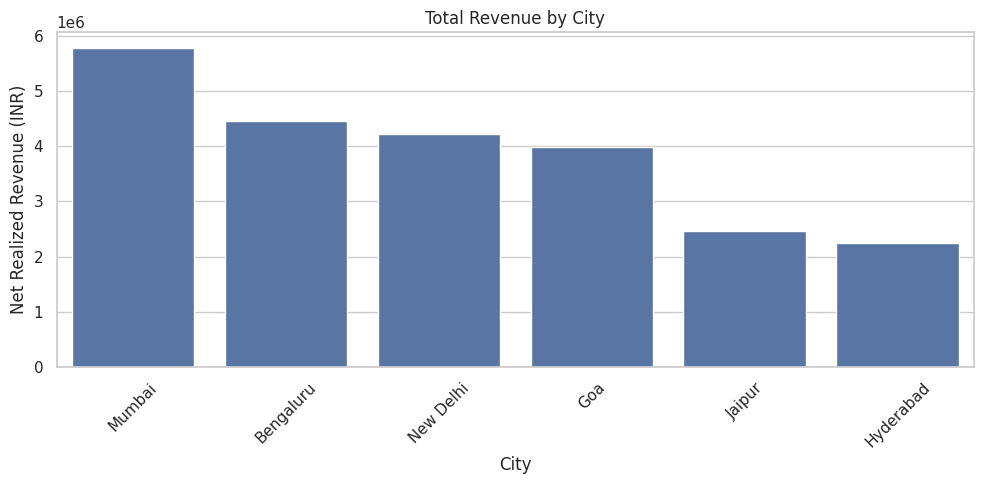

In [13]:
city_revenue = eda_df.groupby('city')[
    'net_realized_revenue_inr'
].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=city_revenue.index,
    y=city_revenue.values
)

plt.title('Total Revenue by City')
plt.xlabel('City')
plt.ylabel('Net Realized Revenue (INR)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

<Figure size 1000x500 with 0 Axes>

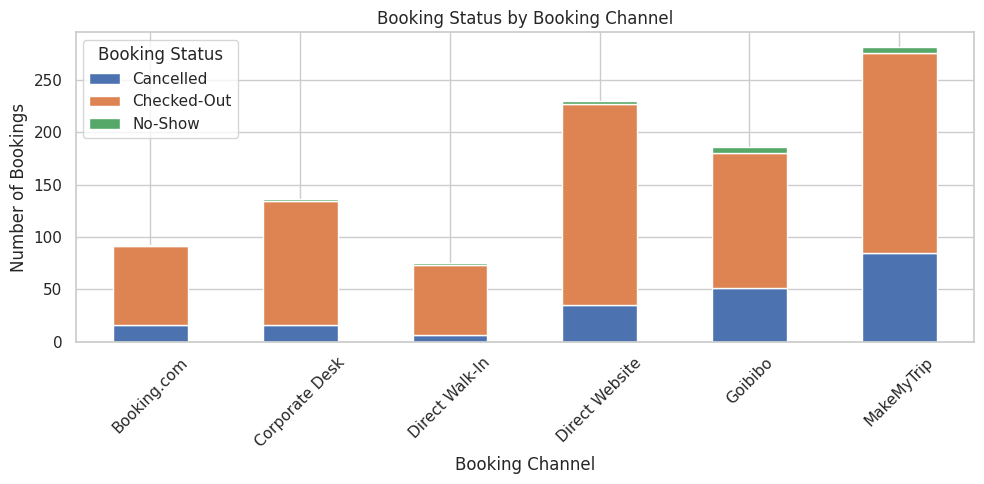

In [14]:
status_channel = pd.crosstab(
    eda_df['booking_channel'],
    eda_df['booking_status']
)

plt.figure(figsize=(10, 5))

status_channel.plot(
    kind='bar',
    figsize=(10, 5),
    stacked=True
)

plt.title('Booking Status by Booking Channel')
plt.xlabel('Booking Channel')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)
plt.legend(title='Booking Status')

plt.tight_layout()
plt.show()

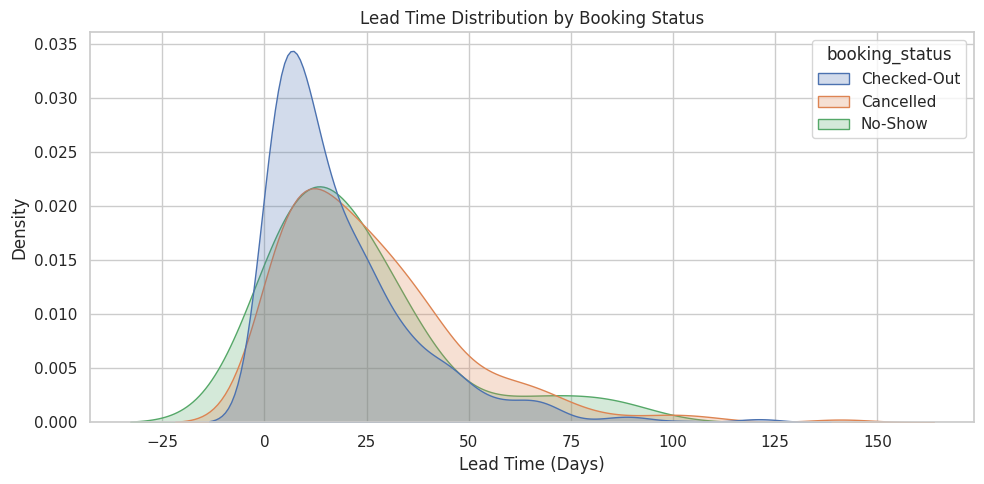

In [15]:
plt.figure(figsize=(10, 5))

sns.kdeplot(
    data=eda_df,
    x='lead_time_days',
    hue='booking_status',
    fill=True,
    common_norm=False
)

plt.title('Lead Time Distribution by Booking Status')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Density')

plt.tight_layout()
plt.show()

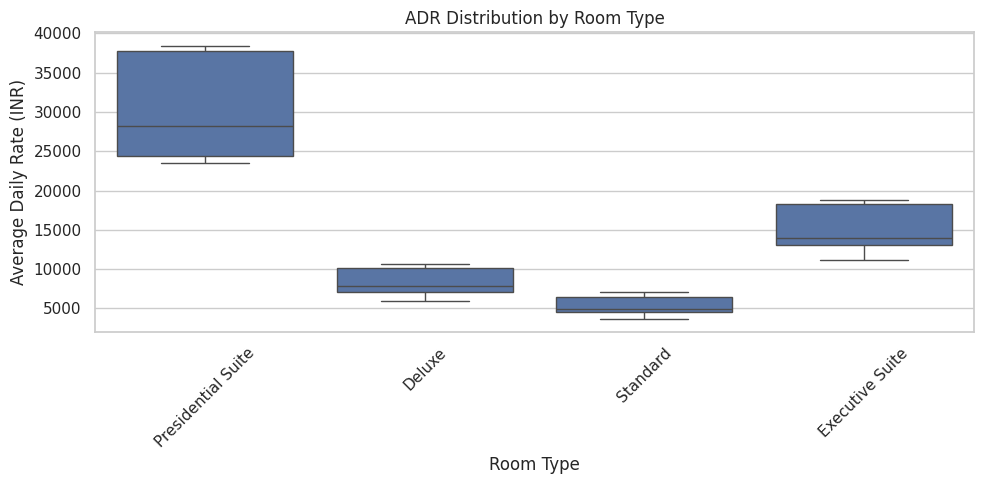

In [16]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=eda_df,
    x='room_type',
    y='adr_inr'
)

plt.title('ADR Distribution by Room Type')
plt.xlabel('Room Type')
plt.ylabel('Average Daily Rate (INR)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [17]:
df_clean.to_csv(
    "hotel_revenue_enterprise_1000_cleaned.csv",
    index=False
)

print("Final cleaned dataset exported successfully!")

Final cleaned dataset exported successfully!


In [18]:
original_df = pd.read_csv(
    "hotel_revenue_enterprise_1000.csv"
)

cleaned_df = pd.read_csv(
    "hotel_revenue_enterprise_1000_cleaned.csv"
)

print("Original Shape:", original_df.shape)
print("Cleaned Shape:", cleaned_df.shape)

print("Same Columns:",
      list(original_df.columns) == list(cleaned_df.columns))

print("Same Data:",
      original_df.equals(cleaned_df))

Original Shape: (1000, 31)
Cleaned Shape: (1000, 31)
Same Columns: True
Same Data: True
